<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/03_tecnicas_resueltas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 03 · Técnicas de RL **resueltas paso a paso**
**Machine Learning — Duoc UC**

En el notebook 02 vimos RL en un problema de juguete (CliffWalking). Los problemas reales son más difíciles. Aquí resolvemos **seis técnicas** sobre dos problemas nuevos, explicando el *por qué* de cada decisión y mostrando qué pasa cuando se hace mal. **Estas son exactamente las herramientas que van a necesitar en el desafío** (notebook 05), pero el desafío no se resuelve copiando: hay que combinarlas, medir y ajustar en su propio entorno.

| Dificultad del problema real | Síntoma | Técnica (sección) |
|---|---|---|
| Demasiados estados | el agente no aprende nada útil con el presupuesto disponible | **1. Agregación / diseño de estado** |
| Falta información en la observación | aprendizaje inestable, resultados distintos entre semillas | **2. Memoria (recuperar la propiedad de Markov)** |
| Una acción que termina el episodio + recompensa tardía | el agente "se rinde" y termina altiro | **3. Inicialización de Q (pesimista/optimista)** |
| Bootstrapping lento en horizontes largos | los valores tardan en propagarse | **4. Monte Carlo vs TD** |
| Interactuar es caro, pero hay datos históricos | se gasta mucho presupuesto aprendiendo lo obvio | **5. RL offline + ajuste online** |
| El mundo cambia | el agente funciona en entrenamiento y falla en producción | **6. Protocolo de evaluación y robustez** |
Monte Carlo contra TD, en la fuente: [David Silver, lecture 4](https://www.youtube.com/watch?v=PnHCvfgC_ZA). En español, [control con Monte Carlo](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/10-control-monte-carlo/). La grilla del notebook 01 ya mostró el síntoma de la técnica 3: con premio al final y castigo por paso, terminar al tiro es una política mala que Q en cero elige igual.


In [1]:
#@title ⚙️ Configuración (ejecutar primero — en Colab clona el repositorio, sin subir archivos)
import os, sys, subprocess, glob

REPO_URL = "https://github.com/Giocrisrai/aprendizaje-refuerzo-duoc"
EN_COLAB = "google.colab" in sys.modules
ARCHIVOS = ("rl_utils.py", "salmon_env.py", "grilla.py", "evolucion.py")
DATOS = (
    "../data/runs_cliffwalking.csv",
    "../data/historial_inventario.csv",
    "../data/historial_operador_salmon.csv",
)

def buscar_notebooks():
    """Carpeta que contiene los .py de la clase, o None."""
    if all(os.path.exists(nombre) for nombre in ARCHIVOS):
        return os.getcwd()
    candidatos = [
        "/content/aprendizaje-refuerzo-duoc/notebooks",
        "/content/rl_aprendizaje_refuerzo/notebooks",
    ]
    candidatos += glob.glob("/content/**/notebooks", recursive=True)
    vistos = []
    for carpeta in candidatos:
        if carpeta in vistos or not os.path.isdir(carpeta):
            continue
        vistos.append(carpeta)
        if all(os.path.exists(os.path.join(carpeta, nombre)) for nombre in ARCHIVOS):
            return carpeta
    return None

if EN_COLAB and buscar_notebooks() is None:
    subprocess.run(
        ["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/aprendizaje-refuerzo-duoc"],
        check=False,
    )

carpeta = buscar_notebooks()
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro " + ", ".join(ARCHIVOS) + ". "
        "En Colab esta celda clona el repositorio: ahí están los módulos y data/. "
        "En el computador, abre el notebook desde la carpeta notebooks/."
    )
os.chdir(carpeta)

if EN_COLAB:
    req = os.path.abspath(os.path.join(os.getcwd(), "..", "requirements.txt"))
    if os.path.exists(req):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", req])
try:
    import numpy, pandas, matplotlib
except ImportError as exc:
    raise ImportError("Faltan numpy, pandas o matplotlib. En local, desde la raíz del repositorio: uv sync --group dev") from exc
faltan = [ruta for ruta in DATOS if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError("Faltan datos del repositorio: " + ", ".join(faltan))
print("✅ Listo. Carpeta de trabajo:", os.getcwd(), "| Colab" if EN_COLAB else "| local")
print("Librerías:", "numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)


✅ Listo. Carpeta de trabajo: /home/claude/rl_clase/notebooks | local


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rl_utils import Inventario, VentaCamioneta

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

def ic95(x):
    x = np.asarray(x, float)
    return 1.96 * x.std(ddof=1) / np.sqrt(len(x))

---
## Problema A: control de inventario de una ferretería (30 días)

- Observación: `(dia, stock, demanda_ayer)`.
- Acción: pedir 0, 3, 6 o 10 unidades. **El pedido llega al día siguiente.**
- Recompensa diaria: ventas × 5 − pedido × 2 − stock × 0,3 − faltantes × 4.
- La demanda media depende del **día de la semana** (el sábado se vende más).

**Línea base** (lo que hace el encargado): "pedir hasta completar S unidades".

In [3]:
def politica_S(S):
    def actuar(obs, accion_anterior):
        objetivo = S - obs[1]
        return int(np.argmin([abs(q - objetivo) for q in Inventario.PEDIDOS]))
    return actuar

def evaluar_inv(actuar, n=300, seed=999, env_kw={}):
    # Evalúa una política (función obs, acción_anterior -> acción) en episodios nuevos.
    env = Inventario(seed=seed, **env_kw)
    R = []
    for _ in range(n):
        o, done, G, ap = env.reset(), False, 0.0, 0
        while not done:
            a = actuar(o, ap)
            o, r, done, _ = env.step(a)
            G += r; ap = a
        R.append(G)
    return np.array(R)

for S in range(6, 19, 2):
    R = evaluar_inv(politica_S(S))
    print(f"S={S:2d}  retorno medio = {R.mean():6.1f} ± {ic95(R):.1f}")

S= 6  retorno medio =  170.7 ± 5.2
S= 8  retorno medio =  215.9 ± 5.2
S=10  retorno medio =  221.1 ± 5.0
S=12  retorno medio =  239.3 ± 4.3
S=14  retorno medio =  233.4 ± 4.3


S=16  retorno medio =  222.8 ± 4.3
S=18  retorno medio =  194.1 ± 4.4


## Técnica 1 · Agregación de estados (diseño del estado)

Q-learning tabular necesita visitar **muchas veces** cada par (estado, acción). Con la observación cruda hay $31 \times 21 \times 15 = 9.765$ estados × 4 acciones ≈ **39.000 celdas** para llenar. Con 30.000 pasos de experiencia, la mayoría de las celdas se visitan 0 o 1 vez.

**Idea:** quedarnos solo con lo que importa para decidir, en la resolución que importa.
- `dia` (0..30) → `dia % 7` (lo relevante es el día de la semana, no el número de día).
- `stock` (0..20) → `stock // 2` (diferencia entre 8 y 9 unidades casi no cambia la decisión).
- `demanda_ayer` → se descarta (la demanda es independiente día a día dado el día de semana).

Resultado: $7 \times 11 = 77$ estados.

Definimos el agente de forma genérica: recibe una **función de features** `f(obs, accion_anterior) -> tupla` y la forma de la tabla Q.

In [4]:
def q_learning_inv(feat, forma, pasos, seed, alpha=0.1, gamma=1.0, Q0=None, eps0=0.3, env_kw={}):
    rng = np.random.default_rng(seed)
    env = Inventario(seed=seed, **env_kw)
    Q = np.zeros(forma) if Q0 is None else Q0.copy()
    usados, curva = 0, []
    while usados < pasos:
        eps = max(0.02, eps0 * (1 - usados / (0.8 * pasos)))
        o, done, ap, G = env.reset(), False, 0, 0.0
        s = feat(o, ap)
        while not done:
            a = int(rng.integers(4)) if rng.random() < eps else int(np.argmax(Q[s]))
            o2, r, done, _ = env.step(a)
            usados += 1; G += r
            s2 = feat(o2, a)
            objetivo = r + (0 if done else gamma * Q[s2].max())
            Q[s + (a,)] += alpha * (objetivo - Q[s + (a,)])
            s = s2
        curva.append((usados, G))
    return Q, curva

def politica_greedy(Q, feat):
    return lambda o, ap: int(np.argmax(Q[feat(o, ap)]))

f_crudo    = lambda o, ap: (o[0], o[1], o[2])
f_agregado = lambda o, ap: (o[0] % 7, min(o[1] // 2, 10))
FORMA = {"crudo": (31, 21, 15, 4), "agregado": (7, 11, 4)}

## Técnica 2 · Memoria: recuperar la propiedad de Markov

Hay un detalle escondido: el pedido de hoy **llega mañana**. Con la observación `(dia, stock, demanda_ayer)` el agente **no sabe** si ayer pidió 0 o 10 unidades, pero eso cambia totalmente lo que conviene pedir hoy.

Cuando la observación no contiene toda la información relevante, el problema es **parcialmente observable (POMDP)**. Q-learning tabular asume que el estado es Markov; si no lo es, el mismo "estado" mezcla situaciones distintas y los valores oscilan.

**Solución típica:** agregar al estado información del pasado que recupera lo que falta — aquí, la **acción anterior** (= lo que viene en camino). En otros problemas puede ser: las últimas k observaciones, una tendencia (sube/baja), un contador ("hace cuántos días que..."), un promedio móvil.

In [5]:
f_memoria = lambda o, ap: (o[0] % 7, min(o[1] // 2, 10), ap)
FORMA["agregado+memoria"] = (7, 11, 4, 4)
FEAT = {"crudo": f_crudo, "agregado": f_agregado, "agregado+memoria": f_memoria}

filas = []
for pasos in [6_000, 30_000, 90_000]:
    for nombre, f in FEAT.items():
        for seed in range(5):
            Q, _ = q_learning_inv(f, FORMA[nombre], pasos, seed)
            R = evaluar_inv(politica_greedy(Q, f))
            filas.append(dict(estado=nombre, pasos=pasos, seed=seed, retorno=R.mean()))
res12 = pd.DataFrame(filas)
tab = res12.groupby(["estado", "pasos"]).retorno.agg(["mean", ic95]).round(1).unstack("pasos")
tab

mean                ic95              
pasos             6000   30000  90000 6000   30000  90000
estado                                                   
agregado           20.6    1.3  -39.1  26.9  124.9  134.5
agregado+memoria  130.9  151.2  186.2  13.4   14.3    7.9
crudo             -87.6 -107.1 -104.2   9.5   22.7   23.1

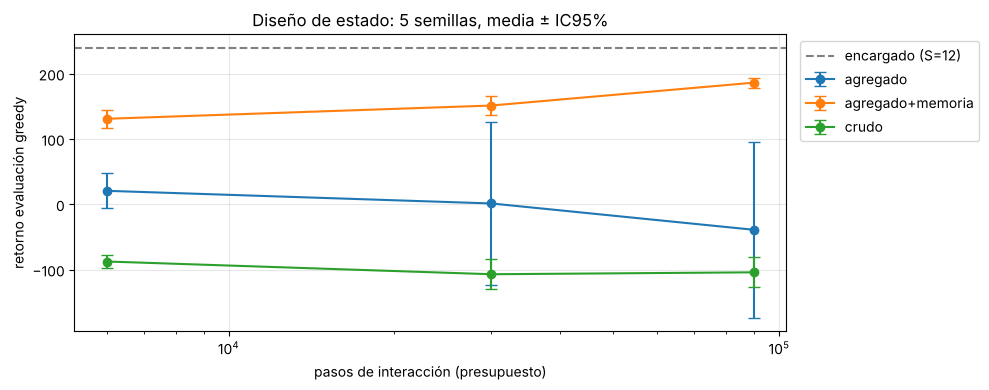

In [6]:
fig, ax = plt.subplots()
for nombre, g in res12.groupby("estado"):
    m = g.groupby("pasos").retorno.agg(["mean", ic95])
    ax.errorbar(m.index, m["mean"], yerr=m["ic95"], marker="o", capsize=4, label=nombre)
ax.axhline(evaluar_inv(politica_S(12)).mean(), ls="--", c="gray", label="encargado (S=12)")
ax.set_xscale("log"); ax.set_xlabel("pasos de interacción (presupuesto)"); ax.set_ylabel("retorno evaluación greedy")
ax.set_title("Diseño de estado: 5 semillas, media ± IC95%"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout();

**Lectura de resultados (para comentar en clase):**
- **Crudo**: no aprende nada útil ni con 90.000 pasos → demasiados estados.
- **Agregado sin memoria**: a veces bien, a veces muy mal → **IC enorme**, señal típica de un estado no-Markov.
- **Agregado + memoria**: aprende rápido y de forma estable.
- Ninguno supera todavía al encargado con este presupuesto... lo arreglamos en la técnica 5.

> **Lección:** antes de cambiar de algoritmo o ajustar hiperparámetros, revisa el **diseño del estado**. Es la decisión que más impacto tiene.

---
## Problema B: vender una camioneta (parada óptima)

Cada día llega una oferta (ruidosa; la media sube hasta el día 15 y luego baja). Puedes **esperar** (cuesta 0,15 por día) o **aceptar** (termina el episodio y recibes la oferta). Si llegas al día 30, la automotora te paga 6,0.

Es la estructura de muchos problemas reales: **cosechar, vender, reemplazar un equipo, lanzar un producto**. Hay una acción que **termina** el episodio y la recompensa importante llega **al final**.

Línea base: "aceptar si la oferta supera un umbral".

In [7]:
def evaluar_venta(actuar, n=1000, seed=999):
    env = VentaCamioneta(seed=seed)
    R, D = [], []
    for _ in range(n):
        o, done, G = env.reset(), False, 0.0
        while not done:
            o, r, done, info = env.step(actuar(o, env))
            G += r
        R.append(G); D.append(info["vendio"])
    return np.array(R), np.array(D)

for umbral in [9.0, 9.5, 10.0, 10.5, 11.0]:
    R, D = evaluar_venta(lambda o, env: int(env.oferta >= umbral or o[0] >= 29))
    print(f"umbral {umbral:4.1f}: retorno {R.mean():.2f} ± {ic95(R):.2f}   día medio de venta {D.mean():.1f}")

umbral  9.0: retorno 9.21 ± 0.04   día medio de venta 3.4
umbral  9.5: retorno 9.34 ± 0.05   día medio de venta 5.4
umbral 10.0: retorno 9.37 ± 0.05   día medio de venta 8.5
umbral 10.5: retorno 9.21 ± 0.09   día medio de venta 12.0


umbral 11.0: retorno 8.43 ± 0.15   día medio de venta 16.5


## Técnica 3 · Inicialización de Q: pesimista, realista, demasiado optimista

Inicializar $Q=0$ parece "neutral", pero **no lo es**. Aquí todas las recompensas finales son positivas (~6–11):

- Aceptar el día 0 entrega ~8 de inmediato → $Q(s,\text{aceptar})\approx 8$ después de probarlo una vez.
- Esperar entrega −0,15 + $\max_a Q(s',a)$, y como $s'$ nunca se visitó, $Q(s',\cdot)=0$ → $Q(s,\text{esperar})\approx -0{,}15$.
- El agente concluye "aceptar siempre" y **nunca vuelve a visitar los días posteriores** para descubrir que eran mejores. Se auto-refuerza.

Con $Q_0$ **optimista** (mayor que el retorno real), lo no explorado "parece bueno" y el agente va a probarlo; la estimación baja hasta su valor real. Pero si es **demasiado** optimista, con un presupuesto finito el agente sigue creyendo que esperar es mejor y vende tarde.

**Regla práctica:** $Q_0 \approx$ una cota superior **plausible** del retorno (aquí, la mejor oferta típica ≈ 10).

In [8]:
def q_learning_venta(Q0, n_episodios, seed, alpha=0.1):
    rng = np.random.default_rng(seed)
    env = VentaCamioneta(seed=seed)
    Q = np.full((30, 10, 2), float(Q0))
    for ep in range(n_episodios):
        eps = max(0.02, 0.3 * (1 - ep / (0.8 * n_episodios)))
        o, done = env.reset(), False
        while not done:
            a = int(rng.integers(2)) if rng.random() < eps else int(np.argmax(Q[o]))
            o2, r, done, _ = env.step(a)
            objetivo = r + (0 if done else Q[o2].max())
            Q[o + (a,)] += alpha * (objetivo - Q[o + (a,)])
            o = o2
    return Q

filas = []
for Q0 in [0, 5, 10, 12, 15]:
    for seed in range(5):
        Q = q_learning_venta(Q0, 3000, seed)
        R, D = evaluar_venta(lambda o, env: int(np.argmax(Q[o])))
        filas.append(dict(Q0=Q0, seed=seed, retorno=R.mean(), dia_venta=D.mean()))
res3 = pd.DataFrame(filas).groupby("Q0")[["retorno", "dia_venta"]].mean().round(2)
res3

,retorno,dia_venta
Q0,,
0,8.03,0.05
5,8.35,0.29
10,9.36,5.10
12,8.74,13.19
15,7.14,19.30


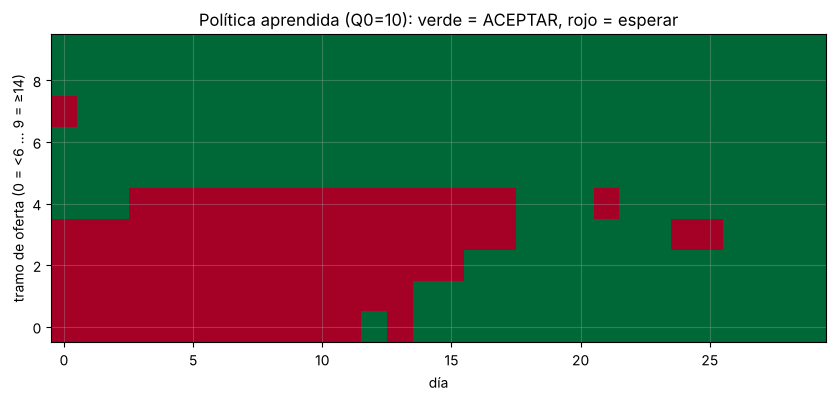

In [9]:
Q_ok = q_learning_venta(10, 3000, seed=0)
fig, ax = plt.subplots()
im = ax.imshow((Q_ok[:, :, 1] >= Q_ok[:, :, 0]).T, origin="lower", aspect="auto", cmap="RdYlGn")
ax.set_xlabel("día"); ax.set_ylabel("tramo de oferta (0 = <6 ... 9 = ≥14)")
ax.set_title("Política aprendida (Q0=10): verde = ACEPTAR, rojo = esperar");

La política aprendida es un **umbral que depende del día**: exigente al principio (vienen mejores ofertas), más flexible al final. Eso es justamente lo que una regla fija ("umbral 10") no puede hacer, y por eso RL tiene sentido aquí.

> Ojo: en la figura aparecen celdas raras (verde/rojo aislados) en zonas **que casi nunca se visitan**. Que la política sea extraña donde no hay datos es normal; lo importante es que sea buena donde el agente realmente pasa.

## Técnica 4 · Monte Carlo vs diferencia temporal (TD)

| | TD (Q-learning, SARSA) | Monte Carlo control |
|---|---|---|
| Objetivo | $r + \gamma \max_{a'} Q(s',a')$ (usa una **estimación**) | $G_t$ = retorno **real** observado hasta el final |
| Sesgo / varianza | sesgo (si $Q(s')$ está mal), baja varianza | sin sesgo de bootstrapping, alta varianza |
| Propagación | la recompensa final viaja **un paso por actualización** hacia atrás | la recompensa final llega a **todos** los pasos del episodio de una vez |
| Sensible a $Q_0$ | mucho (lo vimos arriba) | poco (con promedio $1/N$, el valor inicial se borra en la primera visita) |
| Qué valor aprende | el de la política greedy (Q-learning) | el de la política que **ejecuta**, incluida la exploración (on-policy) |

Implementación de Monte Carlo *every-visit* con promedio incremental:
Para ver la derivación con calma: [David Silver, lecture 4](https://www.youtube.com/watch?v=PnHCvfgC_ZA) y, en español, [Monte Carlo](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/10-control-monte-carlo/).


In [10]:
def montecarlo_venta(n_episodios, seed, prob_aceptar_al_explorar=0.5, eps0=0.3):
    rng = np.random.default_rng(seed)
    env = VentaCamioneta(seed=seed)
    Q = np.zeros((30, 10, 2)); N = np.zeros_like(Q)
    for ep in range(n_episodios):
        eps = max(0.02, eps0 * (1 - ep / (0.8 * n_episodios)))
        o, done, trayectoria = env.reset(), False, []
        while not done:
            if rng.random() < eps:
                a = int(rng.random() < prob_aceptar_al_explorar)
            else:
                a = int(np.argmax(Q[o]))
            o2, r, done, _ = env.step(a)
            trayectoria.append((o, a, r)); o = o2
        G = 0.0
        for s, a, r in reversed(trayectoria):      # recorrer hacia atrás acumulando el retorno
            G += r
            N[s + (a,)] += 1
            Q[s + (a,)] += (G - Q[s + (a,)]) / N[s + (a,)]
    return Q

filas = []
for p in [0.5, 0.1]:
    for seed in range(5):
        Q = montecarlo_venta(3000, seed, prob_aceptar_al_explorar=p)
        R, D = evaluar_venta(lambda o, env: int(np.argmax(Q[o])))
        filas.append(dict(metodo=f"MC (explorar: aceptar con p={p})", retorno=R.mean(), dia_venta=D.mean()))
pd.DataFrame(filas).groupby("metodo").mean().round(2)

,retorno,dia_venta
metodo,,
MC (explorar: aceptar con p=0.1),8.62,0.99
MC (explorar: aceptar con p=0.5),8.74,0.93


**¿Por qué Monte Carlo rinde peor aquí (~8,7 vs ~9,4 de Q-learning con $Q_0=10$)?** Aprende el valor de la política **que explora**. Mientras explora, a veces acepta ofertas malas, entonces "esperar" se ve peor de lo que realmente es si después uno decide bien. Ese sesgo pesimista se arrastra.

**¿Entonces MC no sirve?** Sirve, y mucho, cuando:
- el horizonte es **largo** (decenas de pasos) y la recompensa está concentrada **al final** → TD propaga muy lento;
- es difícil elegir un $Q_0$ razonable;
- se reduce la exploración "dañina" (por ejemplo, explorar casi nunca la acción terminal, o solo al inicio).

No hay un algoritmo ganador universal: **se prueba, se mide y se decide con datos**. (Pista para el desafío.)

---
## Técnica 5 · RL offline: aprender de datos históricos y luego ajustar online

Interactuar con el entorno real es caro (dinero, tiempo, riesgo). Muchas veces existe un **registro histórico** de decisiones tomadas por personas. Volvamos al inventario: `historial_inventario.csv` tiene 300 meses de decisiones del encargado (que a veces se equivoca, lo que en RL es **bueno**: da variedad de acciones).

In [11]:
hist = pd.read_csv("../data/historial_inventario.csv")
print(hist.shape)
hist.head()

(9000, 11)


,episodio,dia,stock,demanda_ayer,accion,pedido,recompensa,dia_sig,stock_sig,demanda_ayer_sig,terminado
0,0,0,8,3,1,3,12.8,1,4,4,0
1,0,1,4,4,2,6,-8.8,2,6,1,0
2,0,2,6,1,2,6,10.9,3,7,5,0
3,0,3,7,5,0,0,33.2,4,6,7,0
4,0,4,6,7,2,6,2.1,5,3,3,0


In [12]:
print("Distribución de acciones del encargado:")
print(hist.accion.value_counts(normalize=True).sort_index().round(3))
print("\nRetorno medio por mes en el historial:", hist.groupby("episodio").recompensa.sum().mean().round(1))

Distribución de acciones del encargado:
accion
0    0.300
1    0.233
2    0.246
3    0.221
Name: proportion, dtype: float64

Retorno medio por mes en el historial: 237.0


**Paso 1: reconstruir el estado con memoria.** El historial no trae la acción anterior, pero se puede calcular agrupando por episodio. (Error típico: hacer `shift` sin agrupar y mezclar el último día de un mes con el primero del siguiente.)

**Paso 2: Iteración Q ajustada (*Fitted Q Iteration*) tabular.** Repetimos sobre **todas** las transiciones guardadas:

$$Q_{k+1}(s,a) = \operatorname{promedio}_{(s,a,r,s') \in \mathcal{D}} \big[r + \gamma \max_{a'} Q_k(s',a')\big]$$

Es Q-learning, pero sobre un dataset fijo y sin interactuar. Peligro: para pares (s,a) **que no aparecen en los datos** no sabemos nada; si los dejamos en 0 y las recompensas son negativas, el `max` los elegirá por error. Por eso se les asigna un valor **pesimista** (aquí −50): "si nunca se probó, no lo recomiendes".

In [13]:
hist["accion_anterior"] = hist.groupby("episodio")["accion"].shift(1).fillna(0).astype(int)

S  = [f_memoria((r.dia, r.stock, r.demanda_ayer), r.accion_anterior) for r in hist.itertuples()]
S2 = [f_memoria((r.dia_sig, r.stock_sig, r.demanda_ayer_sig), r.accion) for r in hist.itertuples()]
A, R, D = hist.accion.to_numpy(), hist.recompensa.to_numpy(), hist.terminado.to_numpy()
forma = FORMA["agregado+memoria"]

Q_off = np.zeros(forma)
for it in range(40):
    suma, cnt = np.zeros(forma), np.zeros(forma)
    for s, a, r, s2, d in zip(S, A, R, S2, D):
        suma[s + (a,)] += r + (0 if d else Q_off[s2].max())
        cnt[s + (a,)] += 1
    Q_off = np.where(cnt > 0, suma / np.maximum(cnt, 1), -50.0)

print(f"Cobertura: {(cnt > 0).mean():.0%} de los pares (estado, acción) aparecen en el historial")
R_off = evaluar_inv(politica_greedy(Q_off, f_memoria))
print(f"Política offline (0 pasos de interacción): {R_off.mean():.1f} ± {ic95(R_off):.1f}")
print(f"Encargado S=12:                            {evaluar_inv(politica_S(12)).mean():.1f}")

Cobertura: 71% de los pares (estado, acción) aparecen en el historial
Política offline (0 pasos de interacción): 284.7 ± 4.7
Encargado S=12:                            239.3


**Paso 3: ajuste online (warm start).** Partimos de `Q_off` y seguimos aprendiendo con poca exploración y poco presupuesto. Comparamos contra aprender desde cero con el **mismo** presupuesto.

In [14]:
filas = []
for pasos in [3_000, 6_000, 15_000]:
    for seed in range(5):
        Qa, _ = q_learning_inv(f_memoria, forma, pasos, seed)                       # desde cero
        Qb, _ = q_learning_inv(f_memoria, forma, pasos, seed, Q0=Q_off, eps0=0.1)   # desde offline
        filas.append(dict(pasos=pasos, inicio="desde cero", retorno=evaluar_inv(politica_greedy(Qa, f_memoria)).mean()))
        filas.append(dict(pasos=pasos, inicio="desde offline", retorno=evaluar_inv(politica_greedy(Qb, f_memoria)).mean()))
res5 = pd.DataFrame(filas)
res5.groupby(["inicio", "pasos"]).retorno.agg(["mean", ic95]).round(1).unstack("pasos")

mean                ic95            
pasos          3000   6000   15000 3000  6000  15000
inicio                                              
desde cero     117.2  130.9  140.4  13.9  13.4   9.3
desde offline  280.8  279.3  264.8   7.4   4.0  11.3

Con datos históricos se parte **sobre** el nivel del encargado sin gastar presupuesto. Fíjense además que **más ajuste online no siempre mejora** (con 15.000 pasos baja un poco y aumenta la variabilidad): el ajuste online con exploración puede "desaprender". Por eso se guarda la mejor versión **validada**, no la última. **Advertencia (clave para el desafío):** esto funciona porque el historial viene **del mismo entorno**. Si los datos vienen de un sistema con otras condiciones (otra tienda, otro centro, otra temporada), el pre-entrenamiento puede ayudar... o empeorar. Hay que **medirlo**, no suponerlo.

---
## Técnica 6 · Protocolo de evaluación y robustez

1. **Semillas de evaluación ≠ semillas de entrenamiento.**
2. **Política greedy** (sin exploración) para medir la política final.
3. **≥ 5 semillas de entrenamiento** → reportar media ± IC95%.
4. **Contabilizar el presupuesto** de interacciones (incluye todos los experimentos fallidos y la búsqueda de hiperparámetros).
5. **Prueba de estrés:** evaluar con condiciones distintas a las de entrenamiento.

Ejemplo: ¿qué pasa si la demanda sube 30% (por ejemplo, en diciembre)?

In [15]:
demanda_alta = dict(media_demanda=tuple(round(m * 1.3, 1) for m in (3, 3, 4, 4, 6, 8, 2)))
Q_final, _ = q_learning_inv(f_memoria, forma, 15_000, seed=0, Q0=Q_off, eps0=0.1)

for nombre, pol in [("encargado S=12", politica_S(12)),
                    ("RL offline+online", politica_greedy(Q_final, f_memoria))]:
    nominal = evaluar_inv(pol).mean()
    estres = evaluar_inv(pol, env_kw=demanda_alta).mean()
    print(f"{nombre:20s} nominal {nominal:6.1f}  | demanda +30%: {estres:6.1f}")

encargado S=12       nominal  239.3  | demanda +30%:  296.6
RL offline+online    nominal  281.2  | demanda +30%:  355.2


Aquí el agente RL resiste bien el cambio. **No siempre es así**: una política aprendida puede depender de detalles del entorno de entrenamiento que cambian en producción (en el desafío, la evaluación final incluye condiciones distintas a las de entrenamiento). Discutir con el curso: ¿por qué una regla simple a veces es más **robusta** que una política aprendida? ¿Qué harían para que el agente RL sea robusto? (ideas: entrenar con condiciones variables, features que no dependan de un valor fijo, re-entrenar periódicamente, monitorear el retorno en producción).

---
## Checklist antes de empezar el desafío
- [ ] ¿Mi estado es pequeño y tiene la información necesaria (incluida memoria si la observación es incompleta)?
- [ ] ¿Hay una acción terminal? → cuidado con la inicialización y con cuánto se explora esa acción.
- [ ] ¿TD o Monte Carlo? → probar ambos con el **mismo presupuesto** y semillas.
- [ ] ¿Hay datos históricos? ¿Vienen del mismo entorno?
- [ ] ¿Comparo contra líneas base razonables?
- [ ] ¿Evalúo con semillas nuevas, greedy, varias semillas de entrenamiento y una prueba de estrés?
### Si una técnica no quedó clara
| Técnica | Repaso |
|---|---|
| 1 y 2. Estado y memoria | Este notebook. La propiedad de Markov está en el [marco de RL de Hugging Face](https://huggingface.co/learn/deep-rl-course/en/unit1/rl-framework) |
| 3. Q inicial | La camioneta. Es el mismo mecanismo que cosechar el día 0, y que el héroe del notebook 01 si nadie cobra el paso |
| 4. Monte Carlo vs TD | [David Silver, lecture 4](https://www.youtube.com/watch?v=PnHCvfgC_ZA) y [Monte Carlo en Codificando Bits](https://codificandobits.com/curso/aprendizaje-por-refuerzo-nivel-intermedio/10-control-monte-carlo/) |
| 5. Historial | Si los datos no son del mismo entorno, se mide antes de fiarse |
| 6. Cómo reportar | El checklist del notebook 02 |

Este notebook queda **resuelto**: las seis técnicas ya tienen el número en pantalla. La práctica con celda Comprobar es el notebook 04. El trabajo en grupo es el notebook 05.
